# 06 - lncRNA and circRNA in Alzheimer's disease (GSE248417)

Notebooks 01-05 studied **miRNAs**. This notebook extends the project to the other two ncRNA classes in
the proposal: **long non-coding RNAs (lncRNAs)** and **circular RNAs (circRNAs)**.

**Data:** GSE248417, whole-blood total RNA-seq, 49 AD vs 49 controls (described as "matched"), USA.
lncRNA: 48,188 transcripts (FPKM-like); circRNA: 49,443 circRNAs (TPM). Same 98 people in both.

**Important limitations (stated up front):**
- **No age, sex or APOE4** is provided, so confounding cannot be checked or adjusted. Results are ncRNA-only.
- **No independent cohort** with lncRNA/circRNA data exists in this project, so there is no external test.
  All performance numbers come from repeated nested cross-validation and are **exploratory**.
- n = 98 is small relative to tens of thousands of features: estimates are noisy.

**Plan:** (1) QC, (2) single-ncRNA differences, (3) known AD lncRNAs / ciRS-7, (4) AD-vs-NC models
(same 4 algorithms and leakage-free pipeline as notebook 02, nested CV repeated 5x, plus a label-permutation
test), (5) top-10 lncRNAs and top-10 circRNAs using the notebook-03 stability method.

Heavy runs come from `src/run_secondary.py` (cached in `results/models/06_runs/`).

In [1]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score
from statsmodels.stats.multitest import multipletests

from utils import ROOT, FIGURES, load_dataset, load_known_ncrnas
from modeling import bootstrap_auc_ci
from secondary import ALGOS, load_secondary, gene_of
from biomarkers import consensus

RUNS = ROOT / "results" / "models" / "06_runs"
TAB = ROOT / "results" / "tables"
FIG = FIGURES / "06_lnc_circ"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def savefig(n): plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight")
PAL = {"AD": "C3", "NC": "C0"}

## 1. Quality control

In [2]:
raw = {k: load_dataset(f"GSE248417_{k}") for k in ["lncRNA", "circRNA"]}
for k, (X, c) in raw.items():
    tot = X.sum(axis=1)
    print(f"{k}: {X.shape[0]} samples x {X.shape[1]} features | AD {(c.diagnosis=='AD').sum()}, NC {(c.diagnosis=='NC').sum()}"
          f" | zero values {(X.values == 0).mean():.0%} | total per sample: median {tot.median():,.0f}, min {tot.min():,.0f}")
Xc_raw, cc_raw = raw["circRNA"]
failed = Xc_raw.index[Xc_raw.sum(axis=1) < 1e5]
print(f"\ncircRNA samples with (almost) no signal, excluded from circRNA analyses: {len(failed)}",
      cc_raw.loc[failed, 'diagnosis'].value_counts().to_dict())

lncRNA: 98 samples x 48188 features | AD 49, NC 49 | zero values 19% | total per sample: median 4,419,448, min 3,450,735


circRNA: 98 samples x 49443 features | AD 49, NC 49 | zero values 82% | total per sample: median 1,000,000, min 0



circRNA samples with (almost) no signal, excluded from circRNA analyses: 6 {'NC': 4, 'AD': 2}


In [3]:
data = {}
for k in ["lncRNA", "circRNA"]:
    X, y, info = load_secondary(k, top_var=None)       # all detected features (value > 1 in >= 50% of samples)
    data[k] = (X, y)
    print(k, info)

lncRNA {'samples_raw': 98, 'features_raw': 48188, 'features_detected': 26416, 'features_used': 26416, 'n': 98, 'AD': 49, 'NC': 49}


circRNA {'samples_raw': 98, 'features_raw': 49443, 'failed_samples': {'NC': 4, 'AD': 2}, 'features_detected': 7325, 'features_used': 7325, 'n': 92, 'AD': 47, 'NC': 45}


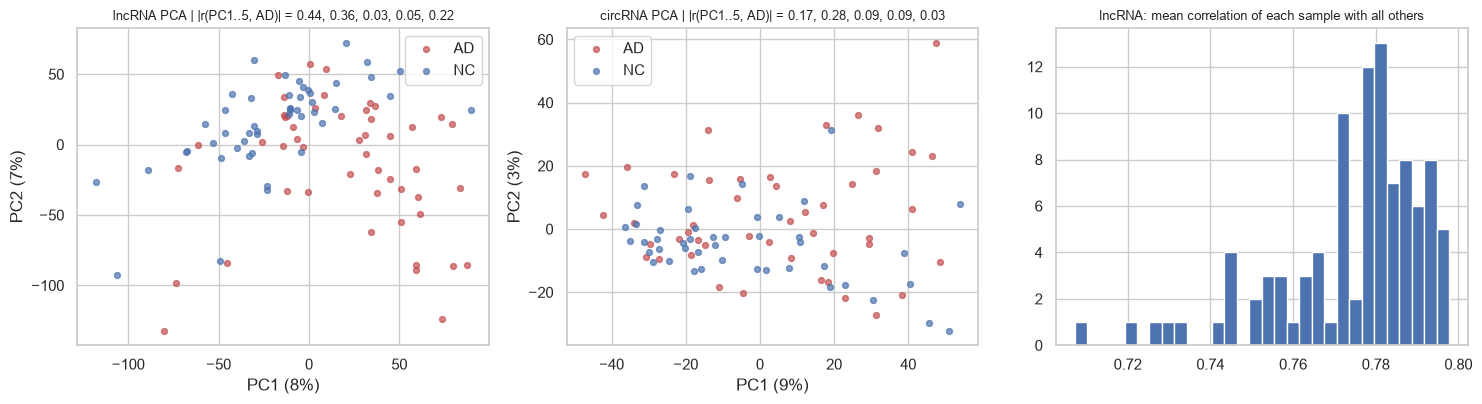

Potential outlier samples (lncRNA, kept): ['GSM7913176', 'GSM7913177', 'GSM7913178', 'GSM7913184', 'GSM7913191', 'GSM7913196', 'GSM7913197', 'GSM7913200', 'GSM7913202', 'GSM7913217', 'GSM7913242', 'GSM7913246', 'GSM7913252']


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, k in zip(axes[:2], ["lncRNA", "circRNA"]):
    X, y = data[k]
    Z = (X - X.mean()) / X.std().replace(0, 1)
    pca = PCA(5).fit(Z); pc = pca.transform(Z)
    for g, lab in [(1, "AD"), (0, "NC")]:
        ax.scatter(pc[y.values == g, 0], pc[y.values == g, 1], s=18, alpha=.7, c=PAL[lab], label=lab)
    r = [abs(stats.pointbiserialr(y, pc[:, i])[0]) for i in range(5)]
    ax.set_title(f"{k} PCA | |r(PC1..5, AD)| = " + ", ".join(f"{v:.2f}" for v in r), fontsize=9)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})"); ax.legend()
# sample-sample correlation outliers (lncRNA)
X, y = data["lncRNA"]
cor = np.corrcoef(X.values); mcor = (cor.sum(1) - 1) / (len(cor) - 1)
axes[2].hist(mcor, bins=30); axes[2].set_title("lncRNA: mean correlation of each sample with all others", fontsize=9)
outl = X.index[mcor < np.median(mcor) - 3 * stats.median_abs_deviation(mcor)]
plt.tight_layout(); savefig("qc_pca"); plt.show()
print("Potential outlier samples (lncRNA, kept):", list(outl))

## 2. Single-ncRNA differences, AD vs NC (Mann-Whitney, Benjamini-Hochberg FDR)

In [5]:
uni = {}
for k, (X, y) in data.items():
    a, b = X[y == 1], X[y == 0]
    u = stats.mannwhitneyu(a, b, axis=0)
    t = pd.DataFrame({"gene": [gene_of(f) for f in X.columns], "log2FC": a.mean() - b.mean(),
                      "auc": u.statistic / (len(a) * len(b)), "p": u.pvalue}, index=X.columns)
    t["fdr"] = multipletests(t.p, method="fdr_bh")[1]
    t = t.sort_values("p"); uni[k] = t
    t.to_csv(TAB / f"06_univariate_{k}.csv")
    print(f"{k}: {len(t)} tested | FDR<0.05: {(t.fdr < .05).sum()} (up {((t.fdr < .05) & (t.log2FC > 0)).sum()}, "
          f"down {((t.fdr < .05) & (t.log2FC < 0)).sum()}) | best single AUC {max(t.auc.max(), 1 - t.auc.min()):.2f}")

lncRNA: 26416 tested | FDR<0.05: 3251 (up 2614, down 637) | best single AUC 0.85


circRNA: 7325 tested | FDR<0.05: 1 (up 1, down 0) | best single AUC 0.77


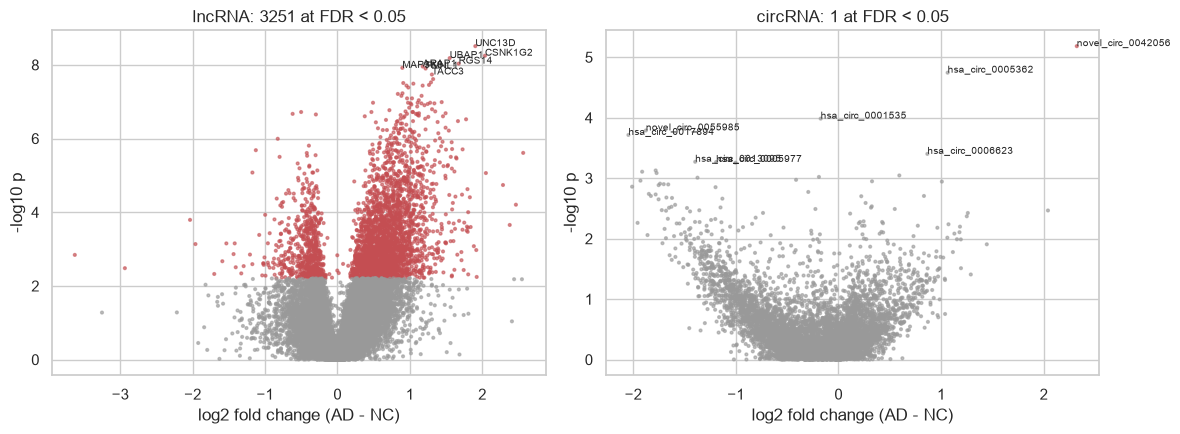

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (k, t) in zip(axes, uni.items()):
    sig = t.fdr < .05
    ax.scatter(t.log2FC, -np.log10(t.p), s=4, c=np.where(sig, "C3", "0.6"), alpha=.6)
    for f in t.index[:8]:
        ax.annotate(t.loc[f, "gene"], (t.loc[f, "log2FC"], -np.log10(t.loc[f, "p"])), fontsize=7)
    ax.set_title(f"{k}: {sig.sum()} at FDR < 0.05"); ax.set_xlabel("log2 fold change (AD - NC)"); ax.set_ylabel("-log10 p")
plt.tight_layout(); savefig("volcano"); plt.show()

In [7]:
pd.concat({k: t.head(10)[["gene", "log2FC", "auc", "fdr"]] for k, t in uni.items()}).round(4)

gene  log2FC     auc     fdr
lncRNA  ENST00000591563|UNC13D-003              UNC13D  1.9055  0.8476  0.0000
        TCONS_00121194|CSNK1G2-OT1             CSNK1G2  2.0392  0.8417  0.0000
        TCONS_00247655|UBAP1-IT2                 UBAP1  1.5517  0.8403  0.0000
        TCONS_00204121|RGS14-IT1                 RGS14  1.6759  0.8367  0.0000
        ENST00000541623|ARAP1-020                ARAP1  1.1792  0.8351  0.0000
        ENST00000578622|MAP3K3-009              MAP3K3  0.8972  0.8342  0.0000
        ENST00000585852|FMNL1-003                FMNL1  1.2186  0.8338  0.0000
        ENST00000404054|TACC3-012                TACC3  1.3057  0.8301  0.0001
        TCONS_00054899|SH2B3-IT1                 SH2B3  1.3228  0.8272  0.0001
        ENST00000574316|DPEP2-010                DPEP2  1.2931  0.8251  0.0001
circRNA novel_circ_0042056          novel_circ_0042056  2.3227  0.7655  0.0480
        hsa_circ_0005362              hsa_circ_0005362  1.0643  0.7598  0.0660
        hsa_circ_0001535              hsa_circ_0001535 -0.1729  0.2648  0.2530
        novel_circ_0055985          novel_circ_0055985 -1.8762  0.2723  0.2825
        hsa_circ_0017894              hsa_circ_0017894 -2.0463  0.2887  0.2825
        hsa_circ_0006623              hsa_circ_0006623  0.8666  0.7147  0.4129
        hsa_circ_0013095              hsa_circ_0013095 -1.3955  0.2905  0.4129
        hsa_circ_0005977              hsa_circ_0005977 -1.1916  0.2908  0.4129
        hsa_circ_0001412              hsa_circ_0001412 -1.0028  0.2908  0.4129
        novel_circ_0033820          novel_circ_0033820 -1.7807  0.3035  0.4129

## 3. Known AD lncRNAs and ciRS-7 (literature list from `data/reference`)

In [8]:
known = load_known_ncrnas()
known = known[known.type.isin(["lncRNA", "circRNA"])]
Xl_raw = raw["lncRNA"][0]
rows = []
for _, r in known.iterrows():
    if r.type == "circRNA":
        feats = [f for f in Xc_raw.columns if f == r["name"]]
    else:
        feats = [f for f in Xl_raw.columns if gene_of(f).upper() == r["name"].upper()]
    if not feats:
        rows.append({"name": r["name"], "type": r.type, "transcripts_measured": 0}); continue
    k = "circRNA" if r.type == "circRNA" else "lncRNA"
    tested = [f for f in feats if f in uni[k].index]
    best = uni[k].loc[tested].sort_values("p").iloc[0] if tested else None
    rows.append({"name": r["name"], "type": r.type, "transcripts_measured": len(feats), "transcripts_detected": len(tested),
                 "best_transcript": best.name if best is not None else None,
                 "log2FC": best.log2FC if best is not None else np.nan, "auc": best.auc if best is not None else np.nan,
                 "p": best.p if best is not None else np.nan, "fdr": best.fdr if best is not None else np.nan,
                 "reported_role": r.reported_role_in_AD})
known_tab = pd.DataFrame(rows)
known_tab.to_csv(TAB / "06_known_lnc_circ.csv", index=False)
known_tab.round(4)

,name,type,transcripts_measured,transcripts_detected,best_transcript,log2FC,auc,p,fdr,reported_role
0,BACE1-AS,lncRNA,2,2.0,ENST00000614401|BACE1-AS-001,0.1914,0.5556,0.3446,0.5935,Stabilizes BACE1 mRNA; increases amyloid-beta
1,MALAT1,lncRNA,19,12.0,ENST00000618132|MALAT1-013,-0.2780,0.3324,0.0043,0.0395,Neuroinflammation and neuronal survival
2,NEAT1,lncRNA,5,2.0,ENST00000499732|NEAT1-002,0.8177,0.6572,0.0074,0.0566,Neuroinflammation; amyloid-beta clearance
3,MEG3,lncRNA,10,2.0,ENST00000522771|MEG3-015,-0.2746,0.4598,0.4924,0.7195,Reported in AD models and neuronal death
4,BCYRN1,lncRNA,1,1.0,ENST00000418539|BCYRN1-001,1.1494,0.7572,0.0000,0.0009,BC200; reported elevated in AD brain
5,SORL1-AS1,lncRNA,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,CDR1-AS,lncRNA,1,0.0,NaN,NaN,NaN,NaN,NaN,Linear CDR1-AS transcript (host of ciRS-7)
7,hsa_circ_0001946,circRNA,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


For each known lncRNA the most significant detected transcript is shown; with several transcripts per
gene, a nominal p < 0.05 is easy to get by chance, so only FDR-significant results count as support.

## 4. Models: AD vs NC (repeated nested cross-validation)

In [9]:
FS = ["lncRNA", "circRNA", "lncRNA+circRNA"]
rows, oofs = [], {}
for fs in FS:
    for algo in ALGOS:
        r = joblib.load(RUNS / f"cv_{fs}_{algo}.joblib")
        y = (load_secondary("lncRNA")[1] if fs == "lncRNA" else load_secondary("circRNA")[1]).loc[r["oof"].index]
        thr = 0.0 if algo == "SVM" else 0.5
        bal = [balanced_accuracy_score(y, r["oof"][c] > thr) for c in r["oof"]]
        ks = pd.Series([p["features__ncrna__select__k"] for p in r["params"]]).value_counts().idxmax()
        rows.append({"feature_set": fs, "algorithm": algo, "AUC_mean": np.mean(r["aucs"]), "AUC_sd": np.std(r["aucs"]),
                     "AUC_min": np.min(r["aucs"]), "AUC_max": np.max(r["aucs"]), "balanced_acc": np.mean(bal),
                     "most_chosen_k": ks})
        oofs[(fs, algo)] = (y, r["oof"])
res = pd.DataFrame(rows)
res.to_csv(TAB / "06_model_comparison.csv", index=False)
res.round(3)

,feature_set,algorithm,AUC_mean,AUC_sd,AUC_min,AUC_max,balanced_acc,most_chosen_k
0,lncRNA,LogReg,0.777,0.023,0.748,0.811,0.757,20
1,lncRNA,RandomForest,0.820,0.011,0.807,0.841,0.765,500
2,lncRNA,SVM,0.763,0.032,0.721,0.814,0.720,500
3,lncRNA,XGBoost,0.786,0.032,0.727,0.820,0.712,500
4,circRNA,LogReg,0.704,0.031,0.658,0.748,0.682,500
5,circRNA,RandomForest,0.664,0.018,0.629,0.679,0.625,500
6,circRNA,SVM,0.659,0.023,0.633,0.692,0.637,500
7,circRNA,XGBoost,0.693,0.023,0.667,0.734,0.639,100
8,lncRNA+circRNA,LogReg,0.765,0.024,0.732,0.805,0.712,500
9,lncRNA+circRNA,RandomForest,0.801,0.017,0.784,0.831,0.762,500


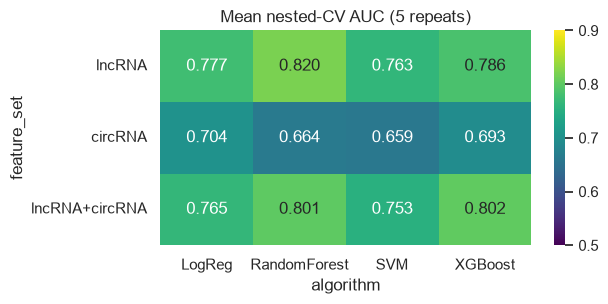

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
sns.heatmap(res.pivot(index="feature_set", columns="algorithm", values="AUC_mean").loc[FS],
            annot=True, fmt=".3f", cmap="viridis", vmin=.5, vmax=.9, ax=ax)
ax.set_title("Mean nested-CV AUC (5 repeats)"); plt.tight_layout(); savefig("auc_heatmap"); plt.show()

**Permutation test.** For the best algorithm of each feature set, the whole nested CV was re-run 20 times
with shuffled AD/NC labels. If real AUCs sit far above this null, the signal is not a by-product of the
pipeline (with 20 permutations the smallest possible p is 1/21 = 0.048).

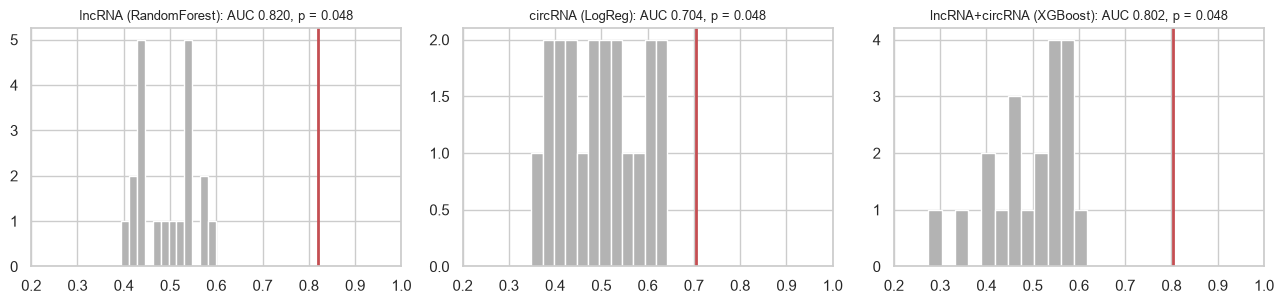

,feature_set,algorithm,AUC,null_mean,null_max,perm_p
0,lncRNA,RandomForest,0.820,0.494,0.600,0.048
1,circRNA,LogReg,0.704,0.496,0.643,0.048
2,lncRNA+circRNA,XGBoost,0.802,0.490,0.618,0.048


In [11]:
perm_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, fs in zip(axes, FS):
    pr = joblib.load(RUNS / f"perm_{fs}.joblib")
    obs = res[(res.feature_set == fs) & (res.algorithm == pr["algo"])].AUC_mean.iloc[0]
    null = np.array(pr["null_aucs"])
    p = (1 + (null >= obs).sum()) / (len(null) + 1)
    perm_rows.append({"feature_set": fs, "algorithm": pr["algo"], "AUC": obs, "null_mean": null.mean(),
                      "null_max": null.max(), "perm_p": p})
    ax.hist(null, bins=12, color="0.7"); ax.axvline(obs, c="C3", lw=2)
    ax.set_title(f"{fs} ({pr['algo']}): AUC {obs:.3f}, p = {p:.3f}", fontsize=9); ax.set_xlim(.2, 1)
plt.tight_layout(); savefig("permutation"); plt.show()
perm = pd.DataFrame(perm_rows); perm.to_csv(TAB / "06_permutation.csv", index=False); perm.round(3)

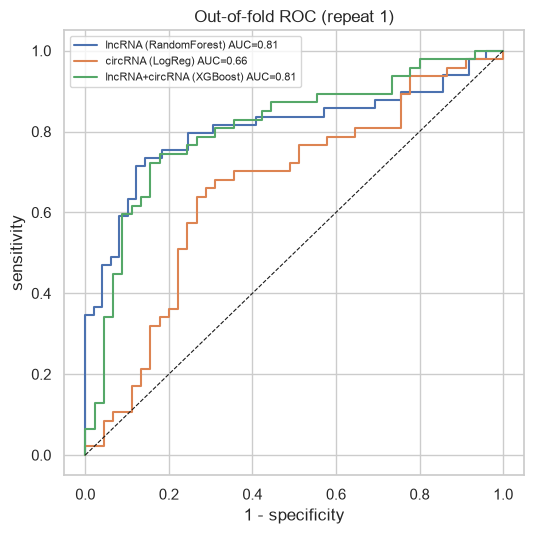

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for fs in FS:
    algo = res[res.feature_set == fs].sort_values("AUC_mean").algorithm.iloc[-1]
    y, oof = oofs[(fs, algo)]
    s = oof[0]; fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, label=f"{fs} ({algo}) AUC={roc_auc_score(y, s):.2f}")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("1 - specificity"); ax.set_ylabel("sensitivity")
ax.legend(fontsize=8); ax.set_title("Out-of-fold ROC (repeat 1)"); plt.tight_layout(); savefig("roc"); plt.show()

## 5. Top-10 lncRNAs and top-10 circRNAs

Same method as notebook 03: LASSO, RFE, Random Forest importance and SHAP, each run on 25 resamples
(5 x 5-fold) of the 5,000 most variable features; a feature qualifies if it is in a method's top 20 in
>= 50% of resamples for >= 2 methods, then ranked by mean selection frequency. No covariates are available.

In [13]:
tops = {}
for k in ["lncRNA", "circRNA"]:
    st = joblib.load(RUNS / f"stability_{k}.joblib")
    table, top10 = consensus(st["freq"], st["mean_rank"])
    t = table.loc[top10].join(uni[k][["gene", "log2FC", "auc", "fdr"]])
    t.insert(0, "rank", range(1, len(t) + 1))
    t["direction_in_AD"] = np.where(t.log2FC > 0, "up", "down")
    tops[k] = t
    t.to_csv(TAB / f"06_top10_{k}.csv")
    print(f"{k}: {table.qualifies.sum()} features qualify; top 10:")
    display(t[["rank", "gene", "direction_in_AD", "log2FC", "auc", "fdr", "freq_LASSO", "freq_RFE", "freq_RF", "freq_SHAP",
               "n_methods_stable"]].round(3))

lncRNA: 17 features qualify; top 10:


,rank,gene,direction_in_AD,log2FC,auc,fdr,freq_LASSO,freq_RFE,freq_RF,freq_SHAP,n_methods_stable
TCONS_00204121|RGS14-IT1,1,RGS14,up,1.676,0.837,0.000,1.0,0.20,0.96,1.00,3
ENST00000591563|UNC13D-003,2,UNC13D,up,1.906,0.848,0.000,1.0,0.72,0.68,0.76,4
TCONS_00121194|CSNK1G2-OT1,3,CSNK1G2,up,2.039,0.842,0.000,1.0,0.52,0.80,0.48,3
ENST00000494142|MBOAT7-003,4,MBOAT7,up,1.265,0.823,0.000,1.0,0.00,0.92,0.88,3
ENST00000591753|COASY-005,5,COASY,up,1.417,0.787,0.000,1.0,0.32,0.56,0.68,3
ENST00000445938|AC017116.11-001,6,AC017116.11,up,1.453,0.784,0.000,1.0,0.56,0.48,0.44,2
TCONS_00072404|C14orf159-OT3,7,C14orf159,up,1.459,0.803,0.000,1.0,0.36,0.52,0.56,3
TCONS_00097685|LINC271,8,LINC271,up,1.322,0.752,0.001,1.0,0.04,0.48,0.84,2
ENST00000449307|GS1-124K5.11-001,9,GS1-124K5.11,up,1.666,0.799,0.000,1.0,0.04,0.64,0.56,3
ENST00000418539|BCYRN1-001,10,BCYRN1,up,1.149,0.757,0.001,1.0,0.56,0.20,0.48,2


circRNA: 9 features qualify; top 10:


,rank,gene,direction_in_AD,log2FC,auc,fdr,freq_LASSO,freq_RFE,freq_RF,freq_SHAP,n_methods_stable
novel_circ_0042056,1,novel_circ_0042056,up,2.323,0.765,0.048,1.0,1.00,0.88,0.96,4
novel_circ_0019129,2,novel_circ_0019129,down,-1.373,0.300,0.413,1.0,0.24,0.76,0.96,3
novel_circ_0018916,3,novel_circ_0018916,up,0.223,0.687,0.469,1.0,0.00,0.80,0.92,3
hsa_circ_0042079,4,hsa_circ_0042079,down,-1.929,0.312,0.413,1.0,0.68,0.24,0.52,3
novel_circ_0033820,5,novel_circ_0033820,down,-1.781,0.304,0.413,1.0,0.16,0.44,0.60,2
novel_circ_0030174,6,novel_circ_0030174,down,-1.714,0.352,0.662,1.0,0.56,0.16,0.32,2
hsa_circ_0001412,7,hsa_circ_0001412,down,-1.003,0.291,0.413,1.0,0.00,0.36,0.52,2
novel_circ_0014594,8,novel_circ_0014594,down,-1.752,0.314,0.413,1.0,0.56,0.08,0.12,2
hsa_circ_0030117,9,hsa_circ_0030117,down,-1.957,0.335,0.587,1.0,0.04,0.20,0.52,2


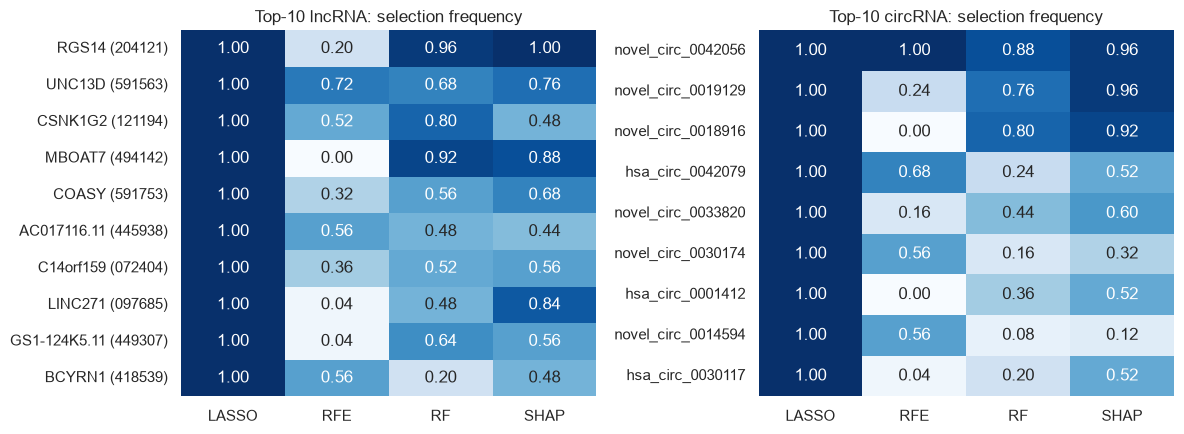

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (k, t) in zip(axes, tops.items()):
    h = t[[f"freq_{m}" for m in ["LASSO", "RFE", "RF", "SHAP"]]].copy()
    h.index = [f"{g} ({i.split('|')[0][-6:]})" if "|" in i else i for i, g in zip(t.index, t.gene)]
    sns.heatmap(h, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Top-10 {k}: selection frequency"); ax.set_xticklabels(["LASSO", "RFE", "RF", "SHAP"])
plt.tight_layout(); savefig("top10_frequency"); plt.show()

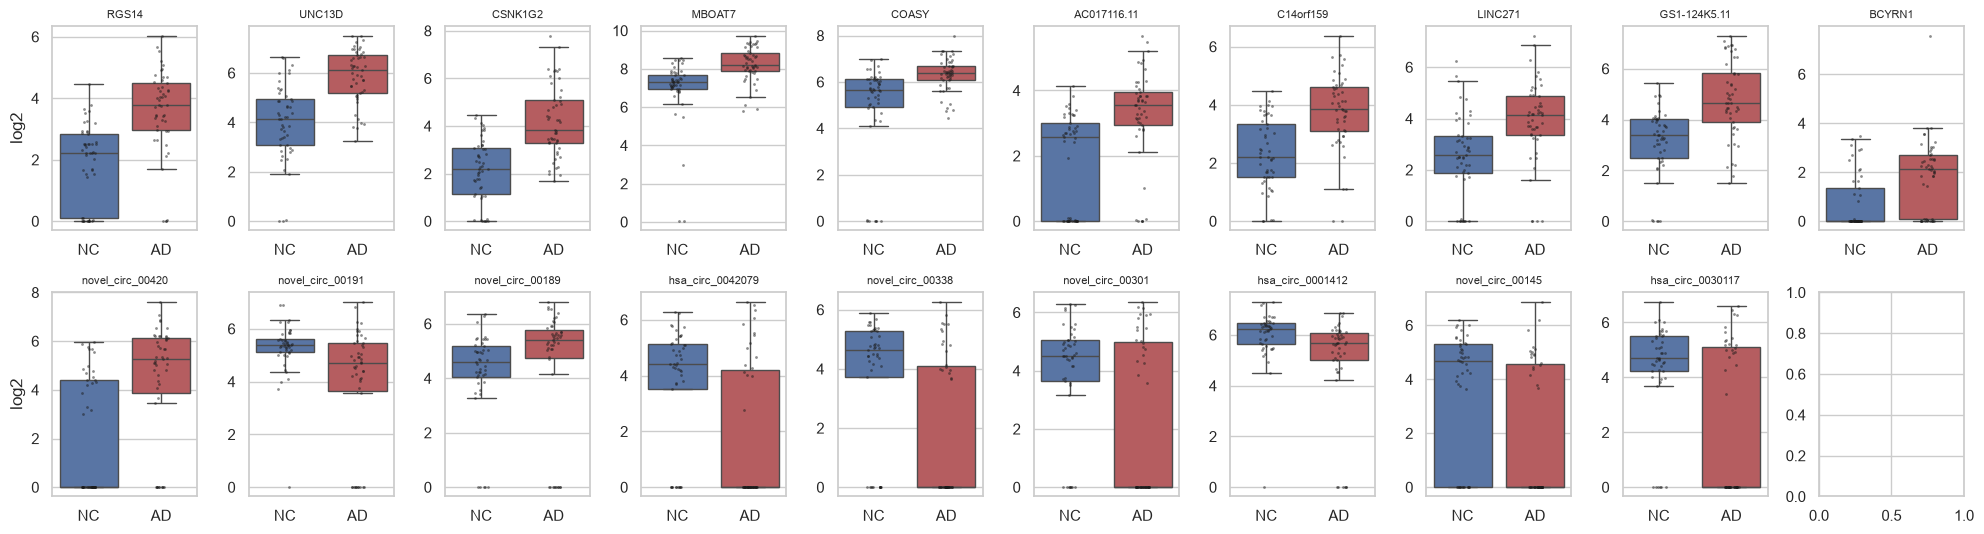

In [15]:
fig, axes = plt.subplots(2, 10, figsize=(20, 5.5), sharey=False)
for row, (k, t) in enumerate(tops.items()):
    X, y = data[k]
    for ax, f in zip(axes[row], t.index):
        d = pd.DataFrame({"v": X[f], "dx": np.where(y == 1, "AD", "NC")})
        sns.boxplot(d, x="dx", y="v", order=["NC", "AD"], palette=PAL, ax=ax, fliersize=0)
        sns.stripplot(d, x="dx", y="v", order=["NC", "AD"], color="k", s=2, alpha=.5, ax=ax)
        ax.set_title(t.loc[f, "gene"][:16], fontsize=8); ax.set_xlabel(""); ax.set_ylabel("log2" if f == t.index[0] else "")
plt.tight_layout(); savefig("top10_boxplots"); plt.show()

In [16]:
known_names = set(n.upper() for n in known["name"])
for k, t in tops.items():
    hit = [g for g in t.gene if g.upper() in known_names]
    print(f"{k}: overlap of top-10 with literature list -> {hit if hit else 'none'}")

lncRNA: overlap of top-10 with literature list -> ['BCYRN1']
circRNA: overlap of top-10 with literature list -> none


## 6. Context: comparison with the miRNA results

In [17]:
mi = pd.read_csv(TAB / "02_model_comparison.csv")
mi_b = mi[mi.feature_set == "B_ncrna"].AUC_mean.max()
best = res.sort_values("AUC_mean").groupby("feature_set").tail(1).set_index("feature_set")
print(f"miRNA only (GSE120584 serum, n=1046, nested CV): best AUC {mi_b:.3f}")
for fs in FS:
    print(f"{fs:15s} (GSE248417 blood, n={len(oofs[(fs, best.loc[fs, 'algorithm'])][0])}): best AUC "
          f"{best.loc[fs, 'AUC_mean']:.3f} +/- {best.loc[fs, 'AUC_sd']:.3f} ({best.loc[fs, 'algorithm']})")

miRNA only (GSE120584 serum, n=1046, nested CV): best AUC 0.850
lncRNA          (GSE248417 blood, n=98): best AUC 0.820 +/- 0.011 (RandomForest)
circRNA         (GSE248417 blood, n=92): best AUC 0.704 +/- 0.031 (LogReg)
lncRNA+circRNA  (GSE248417 blood, n=92): best AUC 0.802 +/- 0.032 (XGBoost)


## 7. Interpretation

**1. lncRNAs carry a strong, above-chance AD signal in blood.** Random Forest on lncRNAs reached
**AUC 0.820 +/- 0.011** (5 repeats of nested CV), balanced accuracy 0.77; all 20 label-shuffled runs scored
<= 0.60 (p = 0.048, the minimum possible with 20 permutations). 3,251 lncRNA transcripts differ at FDR < 0.05.

**2. circRNAs are weak.** Best AUC 0.704 (above chance, p = 0.048) but only **1** circRNA is significant
at FDR < 0.05; the data are 82% zeros and 6 samples failed. Adding circRNAs to lncRNAs did not help
(0.802 vs 0.820). The circRNA top-10 list is unstable (only 9 circRNAs qualified, most not significant alone)
and should not be reported as biomarkers.

**3. Literature support:** **BCYRN1 (BC200)**, reported elevated in AD brain, is higher in AD blood here
(log2FC +1.15, AUC 0.76, FDR 0.001) and is in the lncRNA top 10. NEAT1 is higher in AD (FDR 0.057) and
MALAT1 lower (FDR 0.039). ciRS-7 (hsa_circ_0001946) and CDR1-AS were not detected.

**4. Major caveat: a global shift between groups.** AD samples have higher overall lncRNA levels
(per-sample median 3.98 vs 3.85, p < 1e-6), PC1 correlates with AD (r = 0.44), 80% of significant lncRNAs
go up, and 10 of 13 outlier samples are AD. This can come from a **processing batch** (if AD and control
samples were handled separately), **blood-cell composition**, or **age**, none of which can be checked
because no covariates or batch information are provided. Part of the AUC may therefore not be AD biology.

**5. Limitations:** no age/sex/APOE4, no independent lncRNA/circRNA cohort, n = 98. The top-10 lncRNAs
(e.g. RGS14-IT1, UNC13D-003, CSNK1G2-OT1, MBOAT7-003, BCYRN1) are **hypothesis-generating candidates**.

**Bottom line:** lncRNAs look promising (comparable to miRNAs: AUC 0.82 here vs 0.85 for miRNA-only in
GSE120584), circRNAs do not; both need a covariate-annotated, independent cohort before any biomarker claim.